In [50]:
import warnings
warnings.filterwarnings('ignore')

In [51]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_selector, ColumnTransformer
from sklearn.metrics import roc_curve, roc_auc_score, RocCurveDisplay , accuracy_score
import matplotlib.pyplot as plt
import os

In [52]:
hr=pd.read_csv("D:\Machine Learning\Datasets\HR_comma_sep.csv")
hr

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.10,0.77,6,247,4,0,1,0,sales,low
3,0.92,0.85,5,259,5,0,1,0,sales,low
4,0.89,1.00,5,224,5,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14990,0.40,0.57,2,151,3,0,1,0,support,low
14991,0.37,0.48,2,160,3,0,1,0,support,low
14992,0.37,0.53,2,143,3,0,1,0,support,low
14993,0.11,0.96,6,280,4,0,1,0,support,low


In [53]:
# Human Resource Analysis

from sklearn.metrics import classification_report


X , y = hr.drop('left',axis=1) , hr['left']
ohe = OneHotEncoder(drop='first', sparse_output=False).set_output(transform="pandas")
col_transformer = ColumnTransformer([("OHE", ohe, make_column_selector(dtype_include=object))], 
                                    remainder='passthrough', 
                                    verbose_feature_names_out=False)
col_transformer = col_transformer.set_output(transform="pandas")
X = col_transformer.fit_transform(X)
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.3,random_state=25,stratify=y)
lr = LogisticRegression(solver='liblinear', penalty='l1')
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
print(classification_report(y_test,y_pred))
lr = LogisticRegression(solver='lbfgs', penalty='l2')
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
print(classification_report(y_test,y_pred))


              precision    recall  f1-score   support

           0       0.83      0.93      0.88      3429
           1       0.64      0.37      0.47      1070

    accuracy                           0.80      4499
   macro avg       0.73      0.65      0.68      4499
weighted avg       0.78      0.80      0.78      4499

              precision    recall  f1-score   support

           0       0.84      0.93      0.88      3429
           1       0.65      0.41      0.51      1070

    accuracy                           0.81      4499
   macro avg       0.74      0.67      0.69      4499
weighted avg       0.79      0.81      0.79      4499



In [54]:



solvers = ['newton-cg', 'lbfgs', 'newton-cholesky', 'sag', 'saga']
penalties = ['l2',None]

scores = []

for s in solvers:
    for p in penalties:
        try:
            lr = LogisticRegression(solver=s, penalty=p)
            lr.fit(X_train, y_train)
            y_pred = lr.predict(X_test)
            score = accuracy_score(y_test,y_pred)
            scores.append([s,p,score])
        except:
            continue

df_scores = pd.DataFrame(scores,columns=['Solver','Penalty','Score'])
df_scores.sort_values(by='Score',ascending=False)
df_scores.head()

,Solver,Penalty,Score
0,newton-cg,l2,0.799289
1,newton-cg,None,0.799066
2,lbfgs,l2,0.807735
3,lbfgs,None,0.810180
4,newton-cholesky,l2,0.799066


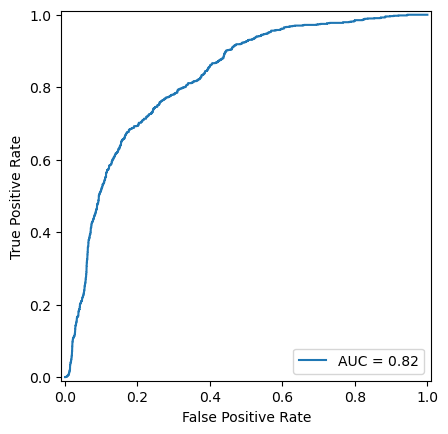

In [55]:
lr = LogisticRegression(solver='liblinear', penalty='l1')
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
fpr , tpr , thres = roc_curve(y_test, lr.predict_proba(X_test)[:,1])
disp = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc_score(y_test, lr.predict_proba(X_test)[:,1]))
disp.plot()
plt.show()

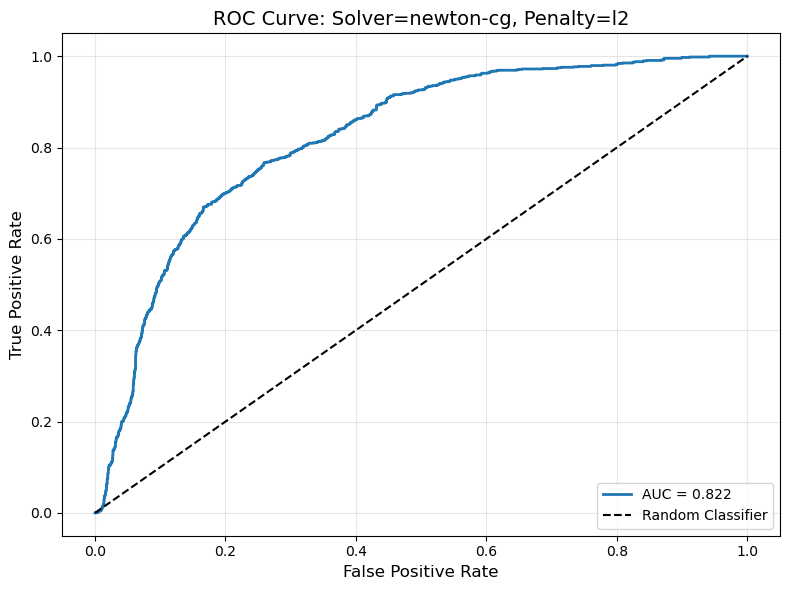

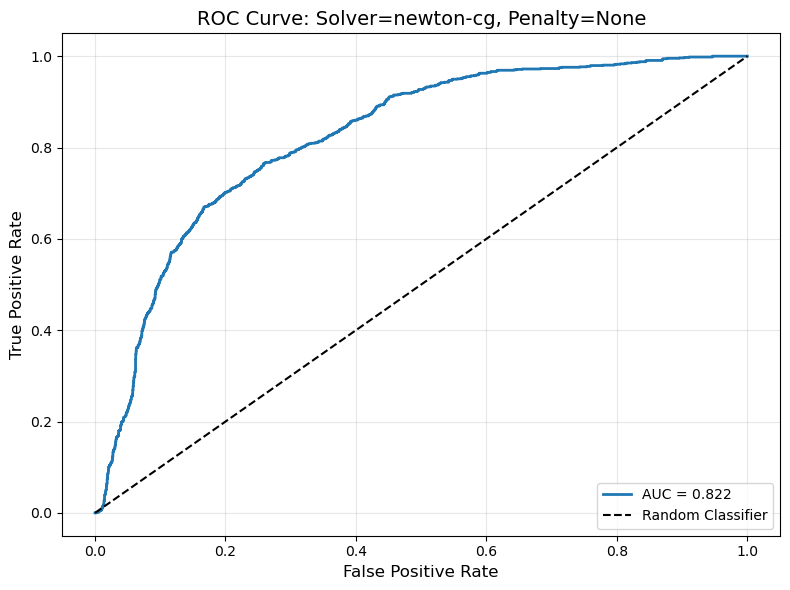

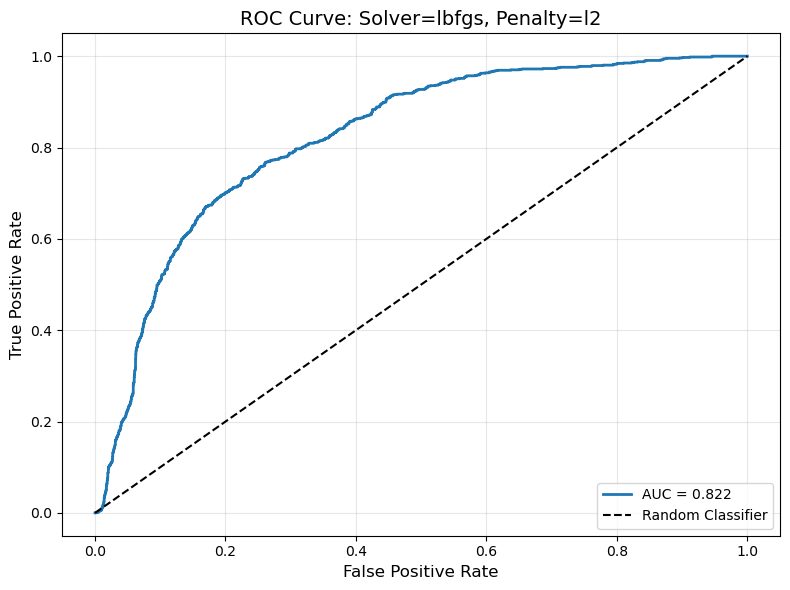

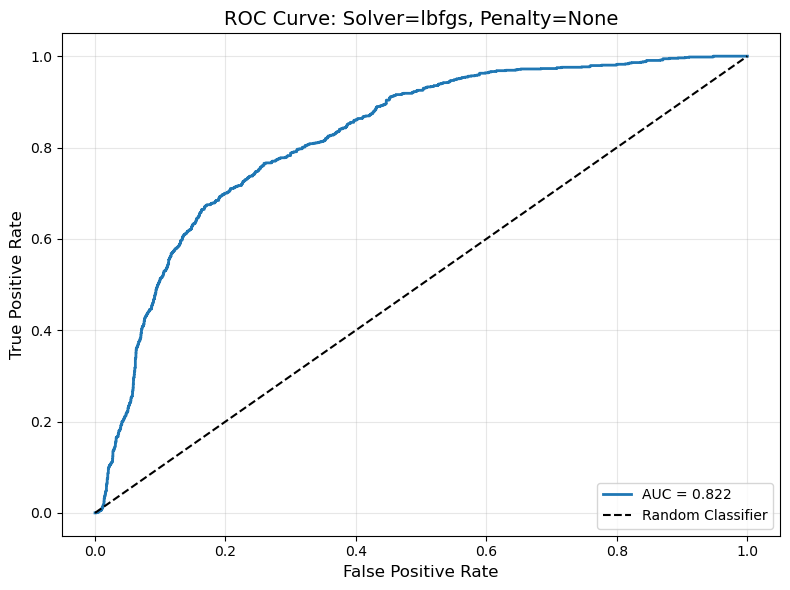

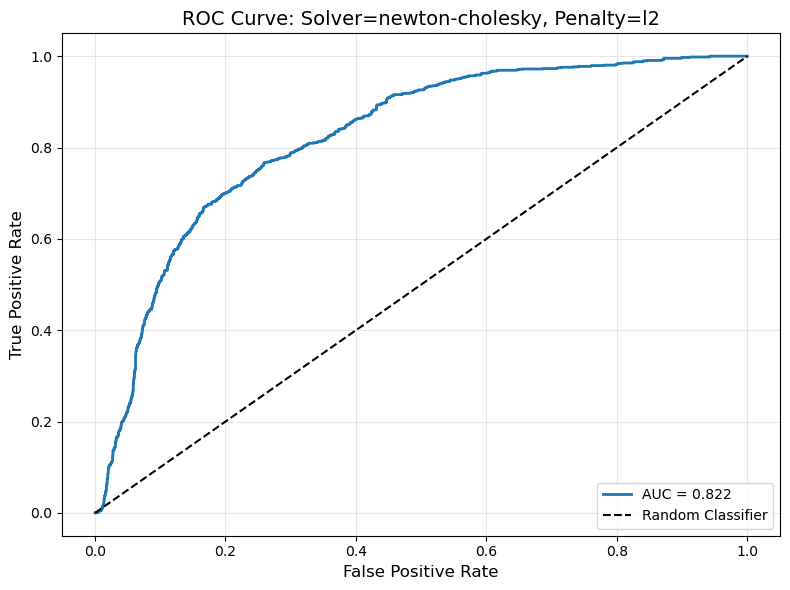

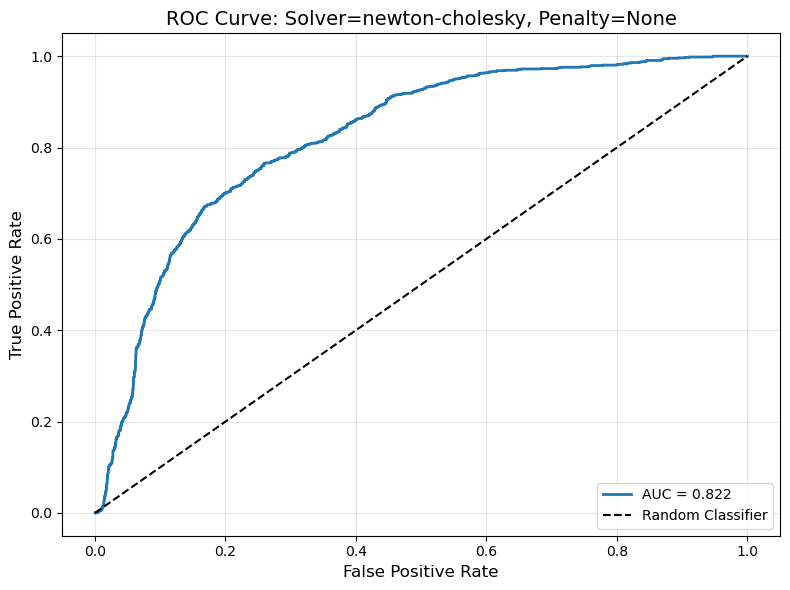

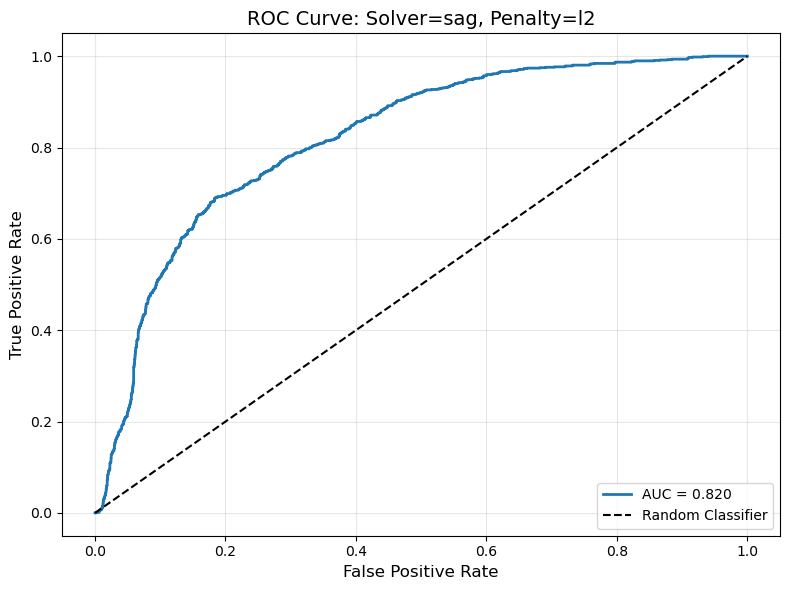

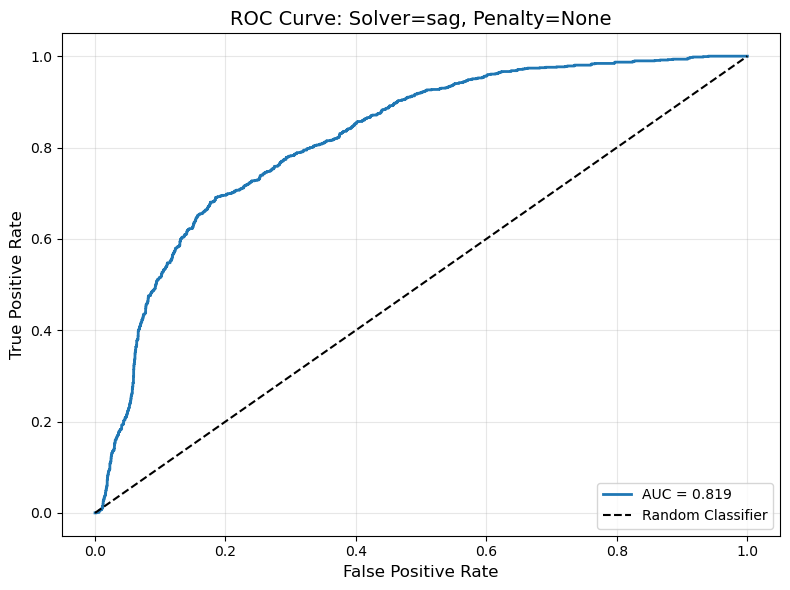

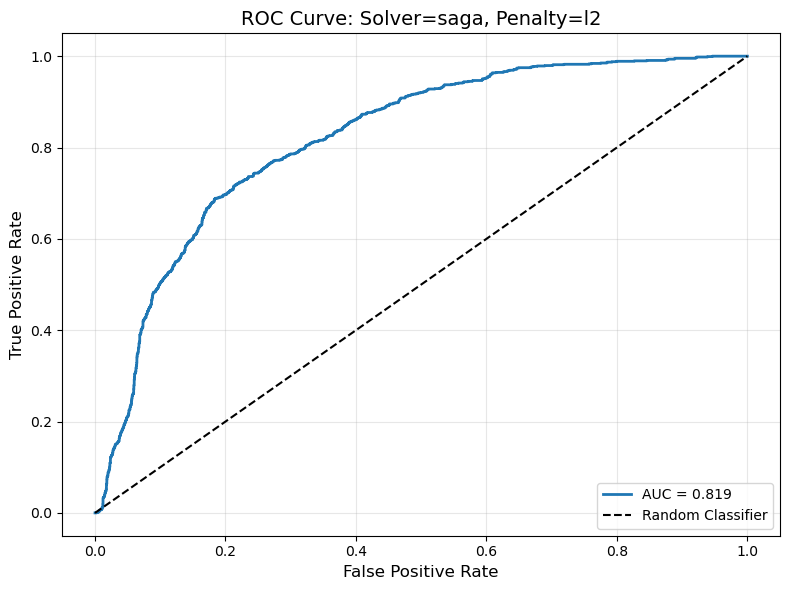

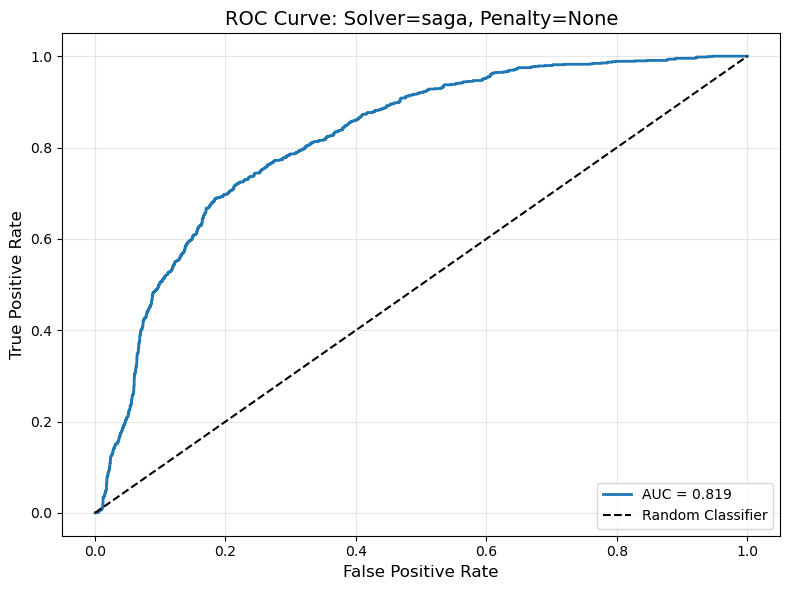


Scores Summary:
         Solver Penalty    Score
          lbfgs      l2 0.822394
      newton-cg    None 0.822274
      newton-cg      l2 0.822272
newton-cholesky      l2 0.822268
newton-cholesky    None 0.822144
          lbfgs    None 0.822111
            sag      l2 0.819510
           saga      l2 0.819368
            sag    None 0.819348
           saga    None 0.819292


In [60]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score
import pandas as pd

solvers = ['newton-cg', 'lbfgs', 'newton-cholesky', 'sag', 'saga']
penalties = ['l2', None]
scores = []

# Create separate figures for each combination
for s in solvers:
    for p in penalties:
        try:
            lr = LogisticRegression(solver=s, penalty=p, max_iter=1000)
            lr.fit(X_train, y_train)
            y_pred_proba = lr.predict_proba(X_test)[:, 1]
            
            # Calculate ROC curve
            fpr, tpr, thres = roc_curve(y_test, y_pred_proba)
            auc_score = roc_auc_score(y_test, y_pred_proba)
            
            # Create separate figure for each combination
            plt.figure(figsize=(8, 6))
            plt.plot(fpr, tpr, linewidth=2, label=f'AUC = {auc_score:.3f}')
            plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
            plt.xlabel('False Positive Rate', fontsize=12)
            plt.ylabel('True Positive Rate', fontsize=12)
            plt.title(f'ROC Curve: Solver={s}, Penalty={p}', fontsize=14)
            plt.legend(loc='lower right', fontsize=10)
            plt.grid(alpha=0.3)
            plt.tight_layout()
            plt.show()
            
            scores.append([s, p, auc_score])
        except Exception as e:
            print(f"Failed: solver={s}, penalty={p}, error={e}")
            continue

# Display scores table
df_scores = pd.DataFrame(scores, columns=['Solver', 'Penalty', 'Score'])
df_scores = df_scores.sort_values(by='Score', ascending=False)
print("\nScores Summary:")
print(df_scores.to_string(index=False))

In [61]:
# log loss
from sklearn.metrics import log_loss
lr = LogisticRegression(solver='liblinear', penalty='l1')
lr.fit(X_train, y_train)
y_pred_proba = lr.predict_proba(X_test)
logloss = log_loss(y_test, y_pred_proba)
logloss

0.42760484954203226